# DatF Project - Part 1

`2026, Block 2`

Your assessment in DatF is based on 4 biweekly assignments. A part of those assignments will be an ongoing project aiming to teach you how to write good code in the context of something larger than your usual day-to-day lab notebooks. 

Specifically we will take a problem you are very familiar with: **using the error propagation formula to estimate uncertainties**, and show you how a powerful programming technique called 'Monte Carlo' simulation can make your scientific work much easier and qualified. 

Using that tool as a concrete starting point, you will learn how to automate the parts of your code that are always the same regardless of the concrete project. In this way, you solve the problem once and then never again have to start e.g. a lab notebook from scratch every time. More importantly, you will learn how to organize and document your code such that it is **reusable**, **sharable**, and **extendable**. As such, your code can become much more valuable to yourself, your future self, your friends, and future scientific colaborators. 

## What to expect from Part 1

The purpose of Part 1 of this project, is to illustrate the power of monte carlo simulation and the potential hazards and inconveniences of applying the error propagation formula. This notebook contains two exercises for you to interact with - please follow it in order and fill out code or markdown blocks as requested. Look for tasks marked with:
> **TASK:** something for you to do ...

The following is a brief recap on the error propagation formula and a highlight of some of its potential issues.


## The error propagation formula

The error propagation formula states, that if a quantity $y$ is a function of some other variables, say $\{ x_1, ..., x_n \}$, such that $y = f(x_1, ..., x_n)$, then if we know the set of expectations $\{ \mu_1, ..., \mu_n \}$ and uncertainties $ \{\sigma_1, ..., \sigma_n\}$ in the input variables, we can calculate the expected output variable $\mu_y$ and its uncertainty $\sigma_y$ as:

$$
y = \mu_y \pm \sigma_y \\
$$

with:

$$
\mu_y = f(\mu_1, ..., \mu_n) \\
$$

and:

$$
\sigma_y = \sqrt{ \left( \frac{\partial f}{\partial x_1} \sigma_1 \right)^2 + \cdots + \left( \frac{\partial f}{\partial x_n} \sigma_n \right)^2}
$$


You have already applied this numerous times in your lab work. However, while the error propagation formula is a great tool, it has certain short commings:

1. **You have to differentiate:** This can be tedious if the quantity you are calculating is a complicated expression - but more importantly: it is not even always possible! What if $f$ it's not differentiable? What if it's not even continuous? Many perfectly reasonable physical examples behave like this but are therefore not directly compatible with the formula.


2. **You are limited to $1^{st}$ order:** While the formula is exact for linear functions, it can produce very wrong predictions if your expression $f$ is sufficiently non-linear.


3. **You are limited to small uncertainties:** If we anyhow apply the formula to non-linear expressions, we must demand that the uncertainties are small such that the function is roughly linear relative to that scale of uncertainty.


4. **You are limited to $\mu \pm \sigma$ summaries:** Quoting a mean and an error bar is fine and meaningful if we imagine a Gaussian error, but what if it is not Gaussian? A distribution is not defined just by its mean and std deviation, and it is not generally true that any function of Gaussian inputs will produce a Gaussian output.


5. **The formula cannot tell you when it falls short:** The formula will always confidently give you a $\mu \pm \sigma$ to quote, but you must decide if that output is meaningful.

The monte carlo method addresses all of these potential issues, although it is not a magical tool such that you dont have to think. To get a better feel for the two, let's get on with the first exercise and start with something familiar.


In [11]:
# import packages
import matplotlib.pyplot as plt
import numpy as np

# Exercise 1 - Estimating the Range of a Canon Ball

**[INSERT ILLUSTRATION]**

Suppose we are launching a canon ball from the ground at an angle $\theta \; [deg]$ and speed $v \; [m/s]$. Assuming no air resistance, the range of the canon ball $R \; [m]$, defined as the horisontal distance it has traveled once it hits the ground again, is given by:

$$

R(v,\theta) = \frac{v^2}{g} \sin (2\theta)

$$

Where $g = 9.82 \; m/s^2$ is the gravitational acceleration. Say that we know the launch angle $\theta$ and speed $v$ with some uncertainties and we want to estimate the resulting uncertainty in the range. 

> **TASK 1:** derive an expression for the uncertainty $\sigma_R$ using the error propagation formula.


> **ANSWER for TAs:**
> 
> $$
> \sigma_R = \sqrt{\left(\frac{2v}{g}\sin(2\theta)\sigma_v \right)^2 + \left( \frac{2v^2}{g} \cos (2\theta) \sigma_\theta \right)^2}
> $$
> 
> *The purpose here is to suffer differentiating something slightly complicated, and to establish something familiar*
>
> NOTE: it is a bad idea to expand $\sin 2\theta = 2 \sin \theta \cos \theta$ before differentiating!

> **TASK 2:** insert your expression in the cell below and print the estimated range for the pre-defined parameters: $\theta = 35 \pm 1 ^\circ$ and $v = 10.0 \pm 0.1 \; m/s$

In [ ]:
# Estimate the range and its uncertainty using the error propagation formula

rad_per_deg = np.pi / 180         # convert degrees to radians

# declare parameters
theta = 35 * rad_per_deg          # rad
sigma_theta = 1 * rad_per_deg     # rad
v = 10.0                          # m/s 
sigma_v = 0.1                     # m/s 
g = 9.82                          # m/s^2

# calculate the range and its uncertainty
R = (v**2 / g) * np.sin(2 * theta)
sigma_R = ...                     # fill out using your derived expression

# -------------------------------------------------------------------------------------------------------------------
# ANSWER for TAs:
#
sigma_R = np.sqrt((2 * v / g * np.sin(2 * theta) * sigma_v)**2 + (v**2 / g * 2 * np.cos(2 * theta) * sigma_theta)**2)
#
# -------------------------------------------------------------------------------------------------------------------

# print the result
print(f"The estimated range is: {R:.2f} ± {sigma_R:.2f}") # the :.2f syntax formats the output to 2 decimal places


The estimated range is: 9.57 ± 0.23


If you succeded, you should see an estimated range of $9.57 \pm 0.23 \; m$ - great, we have our result! Now, whats the deal with monte carlo simulation?

## Monte Carlo simulation

What is fundamentally going on when we propagate, is that we have some uncertain input variables $\{ x_1, ..., x_n \}$ and want to estimate the resulting uncertainty in an output $y=f(x_1, ..., x_n)$. In the context of a typical lab measurement, we quote a central value ($\mu$) and a std deviation ($\sigma$) with an implicit mental image that the variables are probably normally distributed. That is: the most likely value is $\mu$, but the actual value could be within $\pm 2\sigma$ with roughly $95\%$ probability.

The error propagation formula then aims to answer: **given those input distributions, what is the std deviation of the resulting output distribution?**
It does so, by approximating whatever function $f$ you have as a locally linear one and assuming your input distributions to be relatively narrow (low uncertainty).

The idea in monte carlo simulation is to switch the focus from std deviations over to full **_distributions_** instead - and exploit the fact that it is super easy to generate a lot of random numbers on a computer.

What monte carlo simulation then essentially does is this:

1. define the distributions of your input variables $\{x_1, ..., x_n\}$ (default is typically Gaussian)

2. draw a lot of random values according to those distributions

3. for each set of values, compute $y=f(x_1,...,x_n)$ to get a distribution of $\{ y \}$

4. then compute $\mu$ and $\sigma$ for the output distribution

[INSERT SCHEMATIC DIFFERENCE BETWEEN MC AND EPF]

The code below implements that logic for the canon ball example:


In [13]:
# Estimate the range and its uncertainty using monte carlo simulation

# initialize a random number generator (rng) - set a seed for reproducibility
rng = np.random.default_rng(42)

# define a number of samples to draw
n_samples = 10_000

# draw samples for theta and v from normal distributions
theta_samples = rng.normal(loc=theta, scale=sigma_theta, size=n_samples) # loc is the mean, scale is the standard deviation
v_samples = rng.normal(loc=v, scale=sigma_v, size=n_samples)

# NB: these are now arrays of 10_000 random values each for theta and v, drawn from normal distributions with the specified means and standard deviations

# calculate the range R for all the samples individually
R_samples = []
for i in range(n_samples):
    v_i = v_samples[i]
    theta_i = theta_samples[i]
    R_samples.append(v_i**2 / g * np.sin(2 * theta_i)) # Calculate an R value for each random pair of (v, theta)

# NB: this is now a list of 10_000 R values, representing the distribution of possible ranges given the uncertainties in v and theta

# calculate the mean and standard deviation of the range distribution
R_mean = np.mean(R_samples)
R_std = np.std(R_samples)

# print the result
print(f"The estimated range is: {R_mean:.2f} ± {R_std:.2f}")

The estimated range is: 9.57 ± 0.23


### AMAZING!

It is clear that this method yields the same prediction of $R$ but now with the big advantage that we didn't have to differentiate anything! 

All we did was sample random values according to the underlying distributions and then compute the range for all of those values. 

You might be thinking: *"differentiating the canon ball example wasn't that bad, and I might as well continue doing what I am familiar with"* - but as scientists we can rarely be that lucky.

If we just change the setup slightly and instead fire the canon at a certain height $h$ above the ground, the expression for the range changes to:

$$

R(v,\theta,h) = \frac{v \cos \theta}{g} \left( v \sin \theta + \sqrt{v^2 \sin^2 \theta + 2gh} \right)

$$

**Imagine differentiating that!** Meanwhile, the monte carlo approach remains almost embarrisingly simple: 
- draw random values of $v, \theta, h$
- pass them through the formula for $R$ 
- compute the std deviation of the resulting $R$ distribution.

To get a better sense of the distributions hiding behind the scenes and how they relate to the means and std deviations, let's plot them:

> **TASK 3:** run the cell below to see the generated input and output distributions

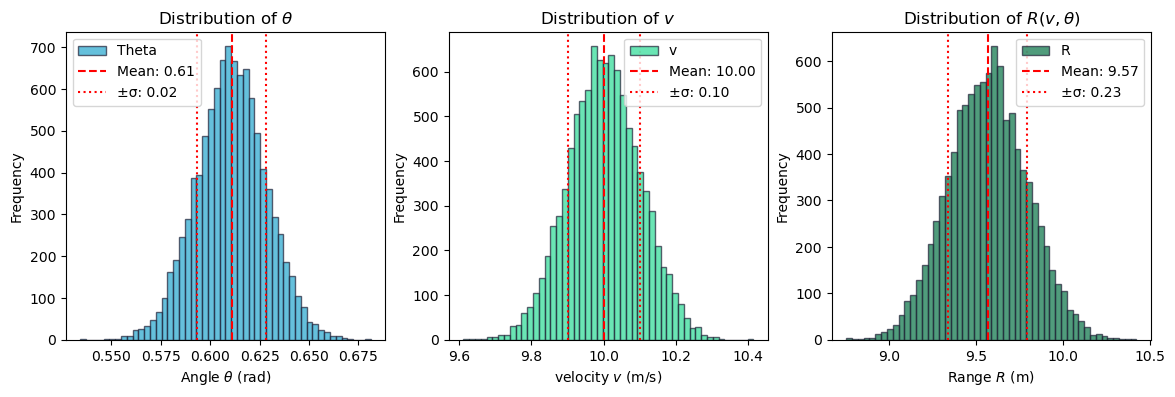

In [14]:
# Plot the distributions of theta, v, and R and mark the mean and standard deviation on the R distribution
plt.figure(figsize=(14, 4))

# Plot the distribution of theta
plt.subplot(1, 3, 1)
plt.hist(theta_samples, bins=50, alpha=0.7, label='Theta', color="#24a6ce", edgecolor="#212137")
plt.axvline(theta, color='red', linestyle='--', label=f'Mean: {theta:.2f}')
plt.axvline(theta + sigma_theta, color='red', linestyle=':', label=f'±σ: {sigma_theta:.2f}')
plt.axvline(theta - sigma_theta, color='red', linestyle=':')
plt.xlabel(r'Angle $\theta$ (rad)')
plt.ylabel('Frequency')
plt.title(r'Distribution of $\theta$')
plt.legend()

# Plot the distribution of v
plt.subplot(1, 3, 2)
plt.hist(v_samples, bins=50, alpha=0.7, label='v', color="#2bdb94", edgecolor="#212137")
plt.axvline(v, color='red', linestyle='--', label=f'Mean: {v:.2f}')
plt.axvline(v + sigma_v, color='red', linestyle=':', label=f'±σ: {sigma_v:.2f}')
plt.axvline(v - sigma_v, color='red', linestyle=':')
plt.xlabel(r'velocity $v$ (m/s)')
plt.ylabel('Frequency')
plt.title(r'Distribution of $v$')
plt.legend()

# Plot the distribution of R
plt.subplot(1, 3, 3)
plt.hist(R_samples, bins=50, alpha=0.7, label='R', color="#067245", edgecolor="#212137")
plt.axvline(R_mean, color='red', linestyle='--', label=f'Mean: {R_mean:.2f}')
plt.axvline(R_mean + R_std, color='red', linestyle=':', label=f'±σ: {R_std:.2f}')
plt.axvline(R_mean - R_std, color='red', linestyle=':')
plt.xlabel(r'Range $R$ (m)')
plt.ylabel('Frequency')
plt.title(r'Distribution of $R(v,\theta)$')
plt.legend()

plt.show()

The two first distributions are the angles and velocities, with the pre-defined means and std deviations indicated in red. These are trivially Gaussian, since we generated them by drawing numbers for a Gaussian distribution.

The output distribution of $R$ however did not have to be Gaussian, but as we can see it turns out that it is and the computed $\mu \pm \sigma$ summary from the error propagation formula is as good a description of the output as it is for the inputs.

**Great! So what, we just don't have to differentiate anymore?**

Well, there is more to it. The real strength of the monte carlo method is that you get to inspect the full distributions and from there make qualified statements about whether the standard $\mu \pm \sigma$ summary is actually a good representation of the output. As mentioned, the error propagation formula can break down once non-linear effects start to kick in. To see this, lets change parameters slightly.

> **TASK 4:** *Read the whole task before doing anything.* 
> 
> Go back to the cell associated with TASK 2 and change parameters to these settings:
> ```python
> theta = 45 * rad_per_deg
> sigma_theta = 10 * rad_per_deg
> v = 10.0
> sigma_v = 0.0
> ```
>
> *We are now expecting to fire the canon at the angle of largest range (45 degs), and for illustration purposes with a larger uncertainty in the angle $\theta$, but __NO__ uncertainty in the speed $v$*.
>
> **Now re-run the cells from TASK 2-4 in order and answer the following questions:**
> - The formula predicts the maximum theoretical range $R=10.18 \; m$ at the $45^\circ$ angle. Why does it predict **zero uncertainty** in $R$ even though the angle is much more uncertain than previously?
> - The monte carlo method predicts the correct std deviation of $0.85 \; m$, but why is the predicted mean at $9.57 \; m$ less than the expected maximum? 
> - Look at the actual output distribution and describe it. Is the $\mu \pm \sigma$ summary a good way to represent the expected range? Why?
> - Try to play around with different settings. When are monte carlo and formula predictions equivalent and when are they not?

> Enter your answers here ...

> **ANSWERS for TAs:**
>
> - There are two contributions to the uncertainty: $\sigma_v$ and $\sigma_\theta$. Here we picked $\sigma_v=0.0$ so there is no contribution. For the angle part, notice that the derivative $\partial f  / \partial \theta = (2v^2/g) \cos 2\theta$ vanishes at the $\theta = 45^\circ$ input. Hence the uncertainty in the angle does not get to contribute. While $f$ has zero local slope, the curvature is substantial over the span of the $\pm 10^\circ$ uncertainty, but the error propagation formula cannot account for effects of higher than first order.
> - the predicted mean is lower than the maximum because all angles that are not $45^\circ$ will fall **shorter** (try to draw the trajectories for slightly larger or smaller angles). This effect is non-linear and illustrates the point, that it generally does not hold that the expected value of a function is the same as the function of the expected value like the error propagation formula asserts ($\mu[f(X)] \neq f(\mu[X])$).
> - the distribution is very non-gaussian with a heavy asymmetry towards lower ranges - this corresponds directly to the mean being lower than the maximum possible range. A symmetric confidence interval is a bad representation since the distribution is not symmetric. The upper value $\mu + \sigma$ is not even physical since it is longer than the theoretical maximum range - it is not possible to shoot that far.

#### **In Summary**

**What this exercise should teach you, is that the error propagation formula can be fine and completely equivalent to the monte carlo method - but only if the first order approximation baked into the formula actually holds. That is, if the function $f$ is roughly linear over the span of all relevant input values.**

**The strength of the monte carlo method is that you become free of differentiation, and that the result - the full output distribution - gives you a way of inspecting exactly how your input uncertainty affects the downstream output.**

# Exercise 2 - Counting Pairs of Photons

Let's look at another example. Suppose we have a source of light in the lab that emits photons at an average rate of 1 photon per second. We record the stream of photons in a detector, and the number of photons per second will follow a Poisson distribution with average rate $\lambda = 1.0$ and a std deviation of $\sigma = \sqrt{\lambda} = 1.0$. Sometimes we recieve 1 photon per second, but other times 0, or 2, or even 6. 

For the sake of a certain experiment, say we are interested in knowing the number of possible photon-pairs that arrive at the detector each second. 

If 1 photon arrives, there is no pair. If 2 photons arrive there is 1 pair. If 3 photons arrive there are 2 possible pairs (combinations of 2), and if 4 photons arrive there are 6 possible pairs, and so forth. In general, given a number of detected photons $n$, the number of possible pairs $P$ follows:

$$
P(n) = \frac{n(n-1)}{2}
$$

The question we want to answer is: *"What is the expected number of possible photon pairs coming from the light source each second?"*.

**[INSERT ILLUSTRATION OF THE SETUP]**

Let's first pull up the error propagation formula with a photon count input described by: $n = 1.0 \pm 1.0$, and the derivative: $dP/dn = (n - 1/2)$

> **TASK 5:** review and run the cell below to produce the error propagation prediction


In [15]:
mean_count = 1.0
sigma_count = 1.0

# function for calculating the number of possible photon pairs
def P(n):
    return n * (n - 1) / 2

# error propagation formula approach
mean_formula = P(mean_count)
sigma_formula = np.sqrt((mean_count - 0.5)**2 * sigma_count**2)

# print the result
print(f"Using the error propagation formula, the estimated number of photon pairs is: {mean_formula:.2f} ± {sigma_formula:.2f}")

Using the error propagation formula, the estimated number of photon pairs is: 0.00 ± 0.50


Alright, so the formula predicts there to be an expected 0.00 number of pairs with a std deviation of 0.50. Now, let's try the monte carlo approach.

> **TASK 6:** fill out the cell below to implement a monte carlo simulation as in the canon ball example

In [16]:
# intialize a random number generator with a seed
rng = ...
n_samples = 10_000

# generate a set of photon counts according to the specified Poisson distribution - hint: look up "numpy random number generator poisson"
count_samples = ...

# transform the photon counts into the number of possible photon pairs by applying the function P to each count sample
pair_samples = []
for i in range(n_samples):
    ...

# calculate the mean and std deviation of the photon pair distribution
mean_pairs = ...
sigma_pairs = ...

# print the result
print(f"...")



...


Well, this is not the error propagation formula prediction - both the expected mean and std deviation are substantially larger! Why is that?
> **TASK 7:** plot histograms of the count_samples and pairs_samples distributions in the cell below and compare with the formula prediction. Explain the differences.

In [17]:
# plot histograms of the photon count and photon pair distributions
... 

> Explain the difference between the error propagation result and the monte carlo result here ...

> **ANSWERS for TAs:**
> 
> The mean and uncertainty is larger for the full Poisson simulation because it has a substantial tail towards higher photon counts. While the Poisson distribution approaches a Gaussian as the average rate $\lambda$ grows larger, this exercise is an example of low count / high uncertainty statistics - the std deviation is as large as the mean $n = 1.0 \pm 1.0$ and approximating the discrete Poisson distribution as a continuous Gaussian is very bad.
>
> However, the real culprit is actually the fact that $P(n)$ is a non-linear function, and the combination between non-linearity and high uncertainty is what causes the first order formula to break down and misrepresent the resulting output.

Imagine now that we have a different light source with a weird non-standard distribution. Instead of a Poisson, it emits 0 photons 50% of the time and 2 photons the other 50% of the time. 

Notice that the expected photon count is still has the same mean and std deviation: $n = 1.0 \pm 1.0$. 

Using the monte carlo method, we can easily accomodate an empirical distribution like this - we just sample the list of outcomes: [0, 2] with replacement. This is known in the business as "bootstrap sampling" - see how we implement it in the cell below: 

In [18]:
# intialize a random number generator with a seed
rng = np.random.default_rng(41)
n_samples = 10_000

# draw samples from the empirical distribution with replacement
empirical_distribution = [0, 2]
empirical_input = rng.choice(empirical_distribution, size=n_samples, replace=True) 

# calculate the number of pairs for each sample
empirical_pairs = []
for i in range(n_samples):
    count = empirical_input[i]
    empirical_pairs.append(P(count))

# estimate the mean and standard deviation of the number of pairs
empirical_mean = np.mean(empirical_pairs)
empirical_std = np.std(empirical_pairs)
print(f"Empirical distribution result: mean = {empirical_mean:.2f}, std = {empirical_std:.2f}")

Empirical distribution result: mean = 0.50, std = 0.50


We now get the same mean prediction as for Poisson, but with a lower std deviation since we never have cases where more than 2 photons are emitted. The photon pair distribution is clearly 50% 0 pairs when there are 0 photons, and 50% 1 pair when there are 2 photons. This is known as a *"bimodal distribution"* and is very different from a Gaussian.

Looking back at the three cases: error propagation formula, poisson simulation, empirical simulation, notice two things:
- the input always had the same $n = 1.0 \pm 1.0$ statistic summary
- the function $P(n)$ we were calculating remained the same

All we changed was **how the input was distributed**, not its mean or std deviation. We must therefore take care when we propagate uncertainties that we don't just propagate an errorbar but model correctly how our variables behave. As such, while the monte carlo method makes the propagation itself trivial, the responsibility of choosing the right statistical models for your use cases still falls to you. 

### **Conclusions**

We hope to have persuaded you by now that monte carlo simulation is a powerful tool worth learning. Here are the key take aways:

#### **What do I gain?**
Never having to differentiate again. In fact, you become able to deal with cases where the output/input relation is not even differentiable at all - or continuous for that matter!

#### **What changes?**
The biggest conceptual change is to propagate **_distributions_ rater than _statistical summaries_** like the mean and standard deviation. Exercise 1 showed that looking at the output distribution can give you much more meaningful information if the result is not a standard Gaussian, and Exercise 2 that different input distributions can give very different output predictions - even if the summary statistics remain the same. Exploiting the ease of generating random numbers on a computer, the act of propagating distributions becomes almost trivial.

#### **So is the error propagation formula just bad?**
No. The formula is a perfectly good approximation but it needs the uncertainties to be small enough that the function $f$ you differentiate is locally linear. In Exercise 1, you saw that the first parameter settings had perfectly well agreement between formula and simulation. The second parameter set however introduced a strong non-linear effect causing the formula to break down and predict both a too high expectation as well as the non-sensical prediction that there was no uncertainty at all ($\sigma_R=0.0$). 

There is nothing special about the canon ball example, many cases you already know can become highly non-linear. For instance a simple ratio: $z = x/y$ with Gaussian variables $x,y$ can produce a very skewed distribution of $z$ if for instance the $y$ distribution has many values near zero that cause $z$ to blow up. Monte carlo simulation shows you that distribution in $z$, but it is only valid to the extend that **you** have modelled $x$ and $y$ correctly. 


# Project Description - build your own reusable python package!

Congratulations on having completed Part 1 of the mandatory project and having gotten more familiar with the monte carlo method. By now you should have a sense that there is a certain structure to the method that is always the same:
- define your inputs
- loop over them and calculate the output
- inspect the output

What changes from project to project is the kinds of inputs and what function $f$ you use to combine them - not the act of propagation itself. This is an opportunity to automate those parts of the code that are always conceptually identical. In these exercises we have come across a few different input types:
- **Constants**: for instance the gravitational acceleration $g$ in Exercise 1. These are numbers that do not change when we compute the output

- **Distributions**: such as the *Gaussian* or *Poisson* distributions, but potentially also weird non-standard ones.

- **Empirical**: a list of observed values a variable can take. We saw a simple case in Exercise 2 but we could also think of having for instance a list of recorded measurements from experimental oberservations. Instead of forcing it to be a Gaussian when it is not - why not just bootstrap sample the recorded distribution?

Rather than writing code from scratch that handles these things for every project, imagine having a little home made python package that does it for you. 
Instead of generating samples and writing for-loops every time, imagine being able to do something like this instead:

```python
from my_own_package import Normal, Poisson, Empirical, propagate # import from your very own package

# define input distributions
x = Normal(1.0, 0.1)
y = Poisson(2.0)
z = Empirical([2.0, 1.9, 2.1, 2.0, 2.0, 1.8, 2.3])

# define your output w = f(x,y,z)
def f(x, y, z):
    return x/y * z**2

w = propagate(f, x, y, z) # ask your package to propagate the uncertainty

# OPTIONALLY:

mu, sigma = w.summarize() # compute mean and std deviation

w.plot() # generate histograms
```
And everything is just taken care of for you. The best part? **You** will have build it yourself! **You** get to decide what everything is called and how it works - your friends and colaborators can even download it and use it just as they use `numpy` or `matplotlib`. 

The ultimate goal is to empower you to write good code that can be **reused** both by others and your future self; code that can be **shared**, downloaded, and run by others; code that is readible and understandable to others; code that others or yourself can take and build new things out of - without having to start from scratch every time. 

Part 2 will be a first step towards this goal using a small library of functions and allow you to write `from my_own_package import ...` and watch it work.